# 🌍 Peak-Based GAT on Raw 3D Seismic Signal
## Animal Footstep Classification — Computationally Lightweight & Edge-Deployable

**Approach:** Instead of computing expensive spectrograms, we work directly on the raw 3D vibration signal `(X, Y, Z)`.  
We compute a 3D **magnitude envelope** using simple arithmetic, detect footstep **peaks** on it, and build a **Graph**.  
A **Graph Attention Network (GAT)** then classifies the entire graph (= one recording) into the correct animal species.

**Why this is computationally lighter than spectrogram-based methods:**
- No FFT required → `O(N)` vs `O(N log N)` per sample
- Smaller input representation (peaks only vs full 2D image)
- Model operates on sparse graph structure, not dense matrices

**Dataset variables (from `dset_allspec_150_chunks_clean.nc`):**
- `chunk(traces, comp, time)` → Raw seismic signal, shape `(N, 3, 2048)` — **this is our input**
- `class(traces)` → Animal class label
- `distance(traces)` → Distance from sensor to animal
- `image(traces, side, side, comp)` → Pre-computed spectrograms (we **do NOT use these**)
- `seis(traces)` → Seismic event ID

## 🖼️ AI Pipeline Architecture

![Binary Unweighted Pipeline](/Users/aaronr/.gemini/antigravity-ide/brain/8225813e-b0e0-48d4-8122-70d326d653e5/binary_unweighted_pipeline_1785084910921.png)

---
## 🔧 CELL 1: Setup & GPU Configuration

In [1]:
import torch, os, numpy as np
print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')

# ── DGX Multi-GPU Auto-Selection: Pick the GPU with the most free VRAM ──
if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    print(f'GPU count       : {num_gpus}')
    best_gpu_idx = 0
    max_free_mem = 0
    
    print('\nChecking VRAM availability across all DGX GPUs:')
    for i in range(num_gpus):
        try:
            free_mem, total_mem = torch.cuda.mem_get_info(i)
            free_gb  = free_mem  / (1024**3)
            total_gb = total_mem / (1024**3)
            print(f'  GPU {i}: {torch.cuda.get_device_name(i):22s} | Free: {free_gb:5.1f} GB / {total_gb:5.1f} GB')
            if free_mem > max_free_mem:
                max_free_mem = free_mem
                best_gpu_idx = i
        except Exception as e:
            print(f'  GPU {i}: Could not query memory ({e})')
            
    device = torch.device(f'cuda:{best_gpu_idx}')
    torch.cuda.set_device(device)
    torch.cuda.empty_cache()   # Clear any leftover cached memory
    print(f'\n🚀 Automatically selected GPU {best_gpu_idx} ({torch.cuda.get_device_name(best_gpu_idx)}) with {max_free_mem/(1024**3):.1f} GB free VRAM!')
else:
    device = torch.device('cpu')
    print('Using device    : cpu')

SEED = 42; torch.manual_seed(SEED); np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print('Setup complete ✓')

PyTorch version : 2.8.0+cu128
CUDA available  : True
GPU count       : 8

Checking VRAM availability across all DGX GPUs:
  GPU 0: Could not query memory (CUDA error: out of memory
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.
)
  GPU 1: NVIDIA A100-SXM4-80GB  | Free:  35.0 GB /  79.2 GB
  GPU 2: NVIDIA A100-SXM4-80GB  | Free:  63.3 GB /  79.2 GB
  GPU 3: NVIDIA A100-SXM4-80GB  | Free:  58.3 GB /  79.2 GB
  GPU 4: NVIDIA A100-SXM4-80GB  | Free:  66.8 GB /  79.2 GB
  GPU 5: NVIDIA A100-SXM4-80GB  | Free:  68.2 GB /  79.2 GB
  GPU 6: NVIDIA A100-SXM4-80GB  | Free:  61.2 GB /  79.2 GB
  GPU 7: NVIDIA A100-SXM4-80GB  | Free:  68.4 GB /  79.2 GB

🚀 Automatically selected GPU 7 (NVIDIA A100-SXM4-80GB) with 68.4 GB free VRAM!
Setup complete ✓


---
## 📂 CELL 2: Load Dataset & Inspect Structure

In [2]:
import netCDF4 as nc
import matplotlib.pyplot as plt

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'
dataset = nc.Dataset(FILE_PATH, mode='r')
print('=' * 60)
print('Dataset Summary')
print('=' * 60)
print(dataset)
print('\nVariables:', list(dataset.variables.keys()))
print('\n' + '-' * 40 + '\nVariable Shapes:')
for v in dataset.variables.keys():
    print(f'  {v:12s}: shape = {dataset.variables[v].shape}, dtype = {dataset.variables[v].dtype}')
print(f'\nchunk[0] shape: {dataset["chunk"][0].shape}  (3 components × 2048 time steps)')
print(f'class[0]      : {dataset["class"][0]}')
print(f'distance[0]   : {dataset["distance"][0]:.2f} meters')
all_labels = dataset['class'][:]
unique_classes, class_counts = np.unique(all_labels, return_counts=True)
print(f'\nTotal recordings : {len(all_labels)}')
print(f'Unique classes   : {unique_classes.tolist()}')
for cls, cnt in zip(unique_classes, class_counts):
    print(f'  Class {cls:3d}: {cnt:6d} samples')

Dataset Summary
<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    dimensions(sizes): time(2048), traces(70637), comp(3), side(128)
    variables(dimensions): float32 chunk(traces, comp, time), int64 class(traces), float32 distance(traces), int64 seis(traces), int64 image(traces, side, side, comp)
    groups: class_dict

Variables: ['chunk', 'class', 'distance', 'seis', 'image']

----------------------------------------
Variable Shapes:
  chunk       : shape = (70637, 3, 2048), dtype = float32
  class       : shape = (70637,), dtype = int64
  distance    : shape = (70637,), dtype = float32
  seis        : shape = (70637,), dtype = int64
  image       : shape = (70637, 128, 128, 3), dtype = int64

chunk[0] shape: (3, 2048)  (3 components × 2048 time steps)
class[0]      : 1
distance[0]   : 145.21 meters

Total recordings : 70637
Unique classes   : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11]
  Class   0:   2073 samples
  Class   1:  62493 samples
  Class   2:    164 

---
## 🗺️ CELL 3: Select Classes & Load Raw Signal Data

In [4]:
SPECIES_NAMES = {0:'Human',1:'Elephant',2:'Giraffe',3:'Lion',4:'Buffalo',
                 5:'Zebra',6:'Wildebeest',7:'Hippo',8:'Cheetah',9:'Hyena'}
SELECTED_CLASSES = [1, 6]   # 0=Human, 1=Elephant (2-class binary)

print('Loading raw signal (chunk) data...')
all_chunks    = dataset['chunk'][:]
all_images    = dataset['image'][:]      # (N, 3, 2048)
all_labels    = dataset['class'][:].astype(int)
all_distances = dataset['distance'][:]
print(f'  chunks  : {all_chunks.shape}')

if SELECTED_CLASSES is not None:
    mask = np.isin(all_labels, SELECTED_CLASSES)
    selected_chunks    = all_chunks[mask]
    selected_images    = all_images[mask]
    selected_labels    = all_labels[mask]
    selected_distances = all_distances[mask]
else:
    SELECTED_CLASSES   = unique_classes.tolist()
    selected_chunks    = all_chunks
    selected_labels    = all_labels
    selected_distances = all_distances

label_map     = {cls: i for i, cls in enumerate(sorted(SELECTED_CLASSES))}
num_classes   = len(label_map)
mapped_labels = np.array([label_map[l] for l in selected_labels])
print(f'Using {len(SELECTED_CLASSES)} classes, {len(selected_labels)} samples total')
print(f'Label mapping: {label_map}')
dataset.close()
print('Data loaded ✓')

Loading raw signal (chunk) data...
  chunks  : (70637, 3, 2048)
Using 2 classes, 66814 samples total
Label mapping: {1: 0, 6: 1}
Data loaded ✓


---
## 📊 CELL 4: Single Sample Visualisation (X, Y, Z + 3D Magnitude)

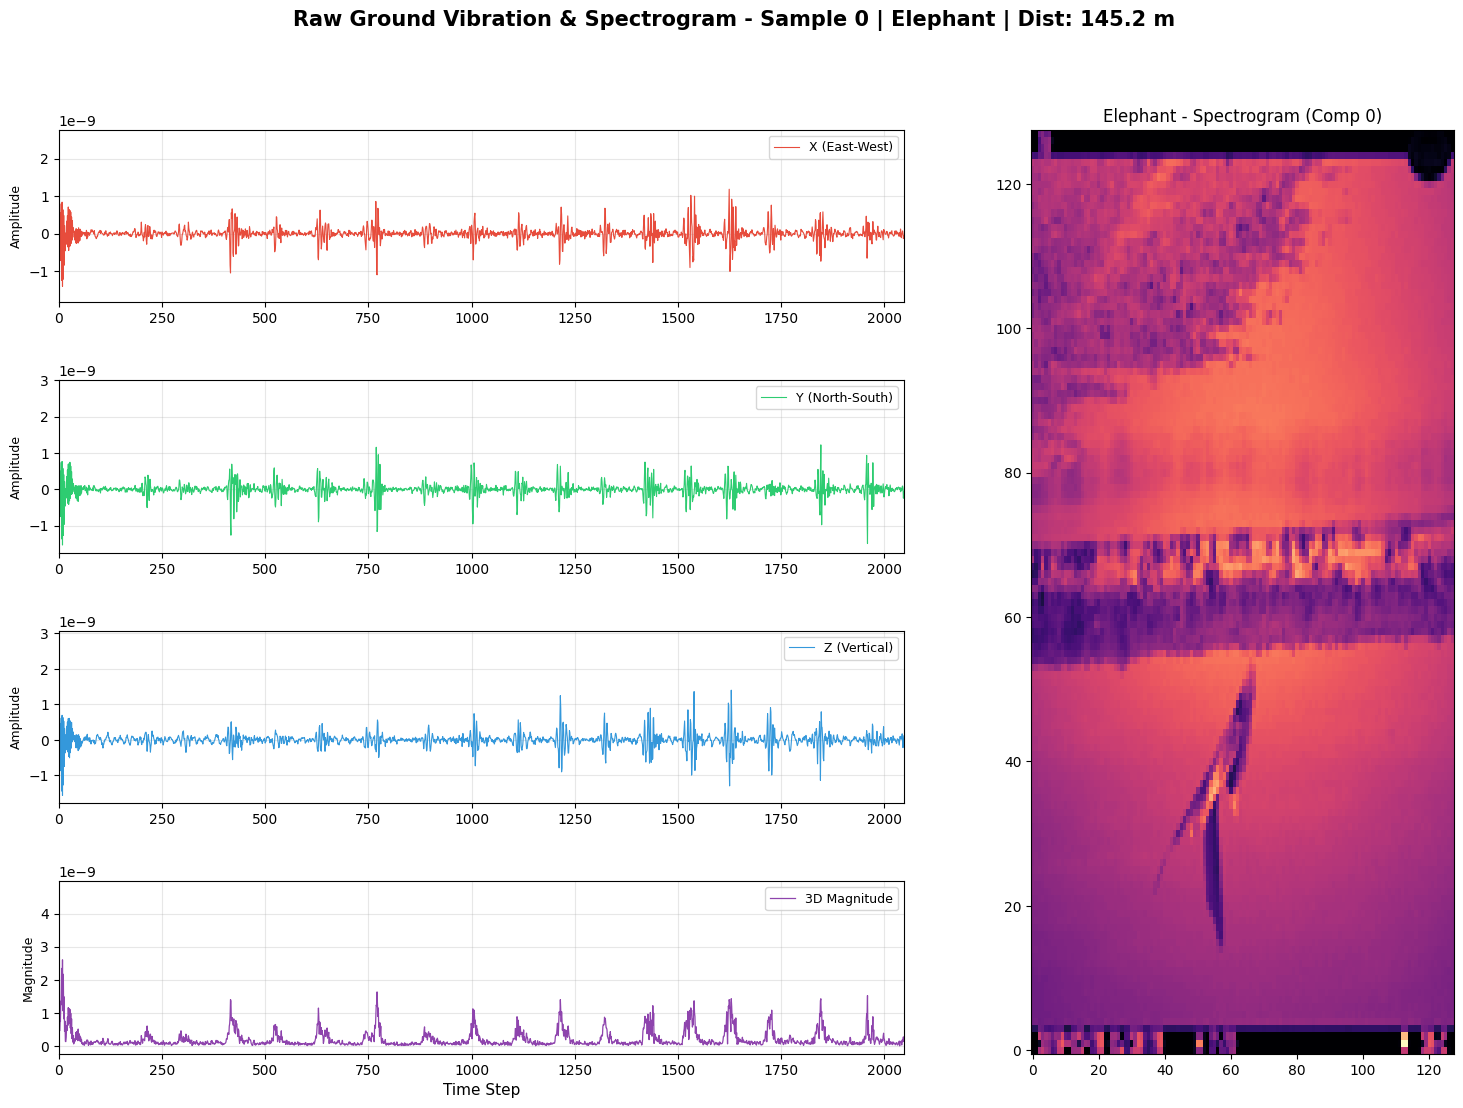

The left shows the raw 3D traces and magnitude used for Peak-GAT.
The right shows the corresponding spectrogram (for visual validation only).


In [5]:
import matplotlib.gridspec as gridspec

sample_idx = 0
signal     = selected_chunks[sample_idx]     # (3, 2048)
image_data = selected_images[sample_idx]     # (side, side, comp)
label      = selected_labels[sample_idx]
distance   = selected_distances[sample_idx]
species    = SPECIES_NAMES.get(int(label), f'Class {label}')
t          = np.arange(signal.shape[1])
magnitude  = np.sqrt(signal[0]**2 + signal[1]**2 + signal[2]**2)

comp_labels = ['X (East-West)', 'Y (North-South)', 'Z (Vertical)']
colors      = ['#e74c3c', '#2ecc71', '#3498db']

fig = plt.figure(figsize=(18, 12))
fig.suptitle(f'Raw Ground Vibration & Spectrogram - Sample {sample_idx} | {species} | Dist: {distance:.1f} m',
             fontsize=15, fontweight='bold')
gs = gridspec.GridSpec(4, 2, width_ratios=[2, 1], hspace=0.45, wspace=0.2)

# Plot X, Y, Z
for i in range(3):
    ax = fig.add_subplot(gs[i, 0])
    ax.plot(t, signal[i], color=colors[i], linewidth=0.8, label=comp_labels[i])
    ax.set_ylabel('Amplitude', fontsize=9); ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3); ax.set_xlim(0, len(t))

# Plot Magnitude
ax4 = fig.add_subplot(gs[3, 0])
ax4.plot(t, magnitude, color='#8e44ad', linewidth=0.9, label='3D Magnitude')
ax4.set_ylabel('Magnitude', fontsize=9); ax4.set_xlabel('Time Step', fontsize=11)
ax4.legend(loc='upper right', fontsize=9); ax4.grid(True, alpha=0.3); ax4.set_xlim(0, len(t))

# Plot Spectrogram (span all 4 rows)
ax_spec = fig.add_subplot(gs[:, 1])
ax_spec.imshow(image_data[:, :, 0], aspect='auto', cmap='magma', origin='lower')
ax_spec.set_title(f'{species} - Spectrogram (Comp 0)', fontsize=12)

plt.savefig(f'binary_visualization_{"weighted" if False else "unweighted"}.png', dpi=150, bbox_inches='tight')
plt.show()
print('The left shows the raw 3D traces and magnitude used for Peak-GAT.')
print('The right shows the corresponding spectrogram (for visual validation only).')


---
## 📊 CELL 5: Species Comparison Grid (X | Y | Z per Class)

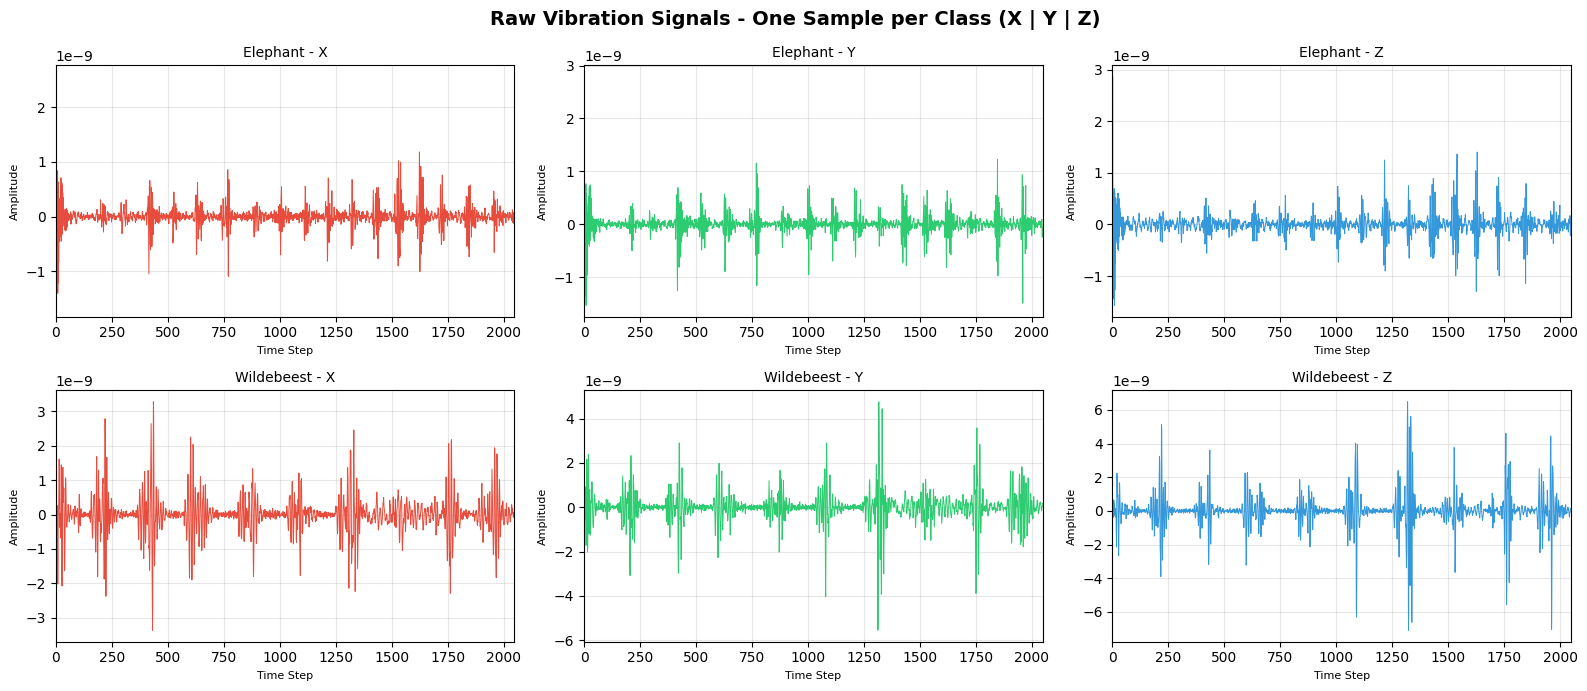

In [6]:
fig, axes = plt.subplots(len(SELECTED_CLASSES), 3, figsize=(16, 3.5 * len(SELECTED_CLASSES)))
if len(SELECTED_CLASSES) == 1: axes = [axes]
fig.suptitle('Raw Vibration Signals - One Sample per Class (X | Y | Z)', fontsize=14, fontweight='bold')
colors = ['#e74c3c', '#2ecc71', '#3498db']; comp_labels = ['X', 'Y', 'Z']

for row, cls in enumerate(SELECTED_CLASSES):
    idx  = np.where(selected_labels == cls)[0][0]
    sig  = selected_chunks[idx]; t = np.arange(sig.shape[1])
    name = SPECIES_NAMES.get(cls, f'Class {cls}')
    for col in range(3):
        ax = axes[row][col]
        ax.plot(t, sig[col], color=colors[col], linewidth=0.7)
        ax.set_title(f'{name} - {comp_labels[col]}', fontsize=10)
        ax.set_xlabel('Time Step', fontsize=8); ax.set_ylabel('Amplitude', fontsize=8)
        ax.grid(True, alpha=0.3); ax.set_xlim(0, len(t))

plt.tight_layout()
plt.savefig('raw_signals_per_class_peak_gat.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 🏔️ CELL 6: Peak Detection Visualisation

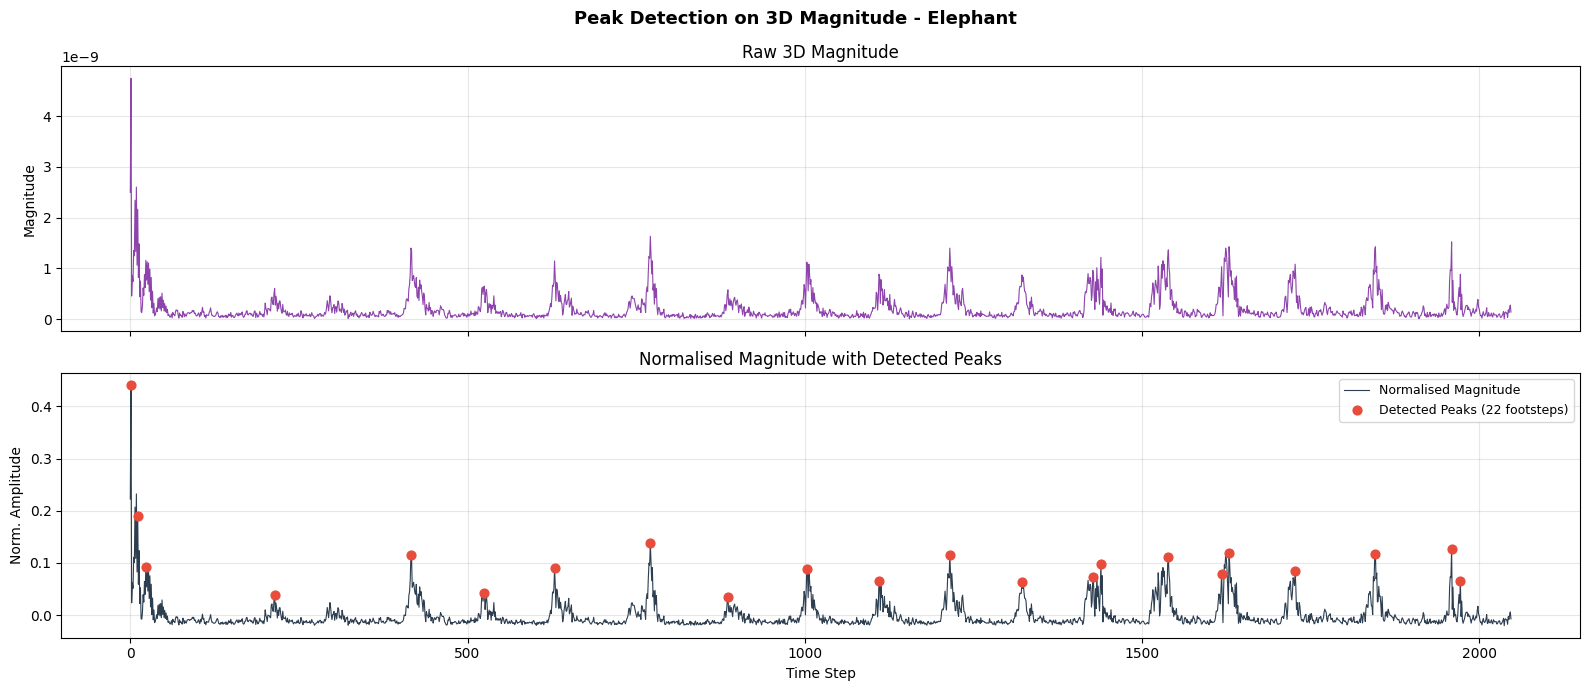

Detected 22 peaks. Each red dot = one footstep impact = one GRAPH NODE.


In [7]:
from scipy.signal import find_peaks

def compute_magnitude(signal_3d):
    return np.sqrt(signal_3d[0]**2 + signal_3d[1]**2 + signal_3d[2]**2)

raw = selected_chunks[0]; mag = compute_magnitude(raw)
mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)
peaks, props = find_peaks(mag_norm, prominence=0.05, distance=10)
t = np.arange(len(mag_norm))

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
fig.suptitle(f'Peak Detection on 3D Magnitude - {SPECIES_NAMES.get(int(selected_labels[0]), "?")}', fontsize=13, fontweight='bold')
axes[0].plot(t, mag, color='#8e44ad', linewidth=0.8)
axes[0].set_title('Raw 3D Magnitude'); axes[0].set_ylabel('Magnitude'); axes[0].grid(True, alpha=0.3)
axes[1].plot(t, mag_norm, color='#2c3e50', linewidth=0.8, label='Normalised Magnitude')
axes[1].scatter(peaks, mag_norm[peaks], color='#e74c3c', zorder=5, s=40, label=f'Detected Peaks ({len(peaks)} footsteps)')
axes[1].set_title('Normalised Magnitude with Detected Peaks')
axes[1].set_ylabel('Norm. Amplitude'); axes[1].set_xlabel('Time Step')
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('peak_detection_demo.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Detected {len(peaks)} peaks. Each red dot = one footstep impact = one GRAPH NODE.')

---
## 🕸️ CELL 7: Graph Extraction Function

**Node Feature Vector (8D):**
- `peak_magnitude` — 3D magnitude at peak
- `peak_X/Y/Z` — Raw amplitude in each axis
- `prominence` — Peak prominence
- `local_energy` — Σ(magnitude²) in ±10 window
- `local_std` — Std of magnitude in ±10 window
- `norm_position` — Normalised time (0→1)

**Edges:**
- Sequential temporal edges (footstep chain)
- k-NN similarity edges (same-type footsteps linked)

In [8]:
from torch_geometric.data import Data
from sklearn.neighbors import kneighbors_graph

NUM_NODE_FEATURES = 8

def extract_raw_peaks_graph(signal_3d, label, prominence=0.05, distance=10, k_neighbors=5, window=10):
    T = signal_3d.shape[1]
    mag = np.sqrt(signal_3d[0]**2 + signal_3d[1]**2 + signal_3d[2]**2)
    mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)
    peaks, props = find_peaks(mag_norm, prominence=prominence, distance=distance)
    if len(peaks) < 2: return None

    node_feats = []
    for i, p in enumerate(peaks):
        lo, hi = max(0, p-window), min(T, p+window)
        win = mag[lo:hi]
        node_feats.append([
            float(mag[p]),
            float(signal_3d[0, p]),
            float(signal_3d[1, p]),
            float(signal_3d[2, p]),
            float(props['prominences'][i]),
            float(np.sum(win**2)) if len(win) > 0 else 0.0,
            float(np.std(win))   if len(win) > 0 else 0.0,
            float(p) / T,
        ])

    x = torch.tensor(node_feats, dtype=torch.float)
    edges, n = [], len(peaks)
    for i in range(n - 1):
        edges.append([i, i+1]); edges.append([i+1, i])
    if n > k_neighbors:
        A = kneighbors_graph(x.numpy(), n_neighbors=k_neighbors, mode='connectivity', include_self=False)
        rows, cols = A.nonzero()
        for r, c in zip(rows, cols): edges.append([r, c])
    if len(edges) == 0: return None

    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    y = torch.tensor([label], dtype=torch.long)
    return Data(x=x, edge_index=edge_index, y=y)

test_g = extract_raw_peaks_graph(selected_chunks[0], mapped_labels[0])
if test_g:
    print('Graph extraction OK')
    print(f'  Nodes: {test_g.num_nodes}, Edges: {test_g.num_edges}, Features: {test_g.num_node_features}')
else:
    print('No graph for sample 0. Adjust prominence/distance parameters.')

Graph extraction OK
  Nodes: 22, Edges: 152, Features: 8


---
## 🏗️ CELL 8: Build Full Graph Dataset & DataLoaders

In [9]:
from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split
from tqdm import tqdm

PROMINENCE  = 0.05; DISTANCE = 10; K_NEIGHBORS = 5; WINDOW = 10
BATCH_SIZE  = 64;  TEST_SIZE = 0.2

print(f'Building graphs from {len(selected_chunks)} raw signals...')
graph_dataset, skipped = [], 0
for i in tqdm(range(len(selected_chunks))):
    g = extract_raw_peaks_graph(selected_chunks[i], mapped_labels[i],
                                prominence=PROMINENCE, distance=DISTANCE,
                                k_neighbors=K_NEIGHBORS, window=WINDOW)
    if g is not None: graph_dataset.append(g)
    else: skipped += 1

print(f'Graphs created: {len(graph_dataset)},  Skipped: {skipped}')

train_graphs, test_graphs = train_test_split(
    graph_dataset, test_size=TEST_SIZE, random_state=SEED,
    stratify=[g.y.item() for g in graph_dataset])

train_loader = DataLoader(train_graphs, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
test_loader  = DataLoader(test_graphs,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f'Train: {len(train_graphs)}, Test: {len(test_graphs)}')
print('DataLoaders created ✓')

Building graphs from 66814 raw signals...


100%|██████████| 66814/66814 [20:33<00:00, 54.15it/s] 


Graphs created: 54901,  Skipped: 11913
Train: 43920, Test: 10981
DataLoaders created ✓


---
## 🧠 CELL 9: Peak-GAT Architecture

In [10]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

class PeakGATRaw(nn.Module):
    def __init__(self, num_node_features, num_classes, hidden_dim=64, num_heads=4, dropout=0.4):
        super().__init__()
        self.gat1 = GATConv(num_node_features, hidden_dim, heads=num_heads, concat=False)
        self.gat2 = GATConv(hidden_dim,        hidden_dim, heads=num_heads, concat=False)
        self.gat3 = GATConv(hidden_dim,        hidden_dim, heads=num_heads, concat=False)
        self.dropout = dropout
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x, edge_index, batch):
        h = F.elu(self.gat1(x, edge_index))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = F.elu(self.gat2(h, edge_index))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = self.gat3(h, edge_index)
        h_graph = torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1)
        return self.classifier(h_graph)

# Clear VRAM cache before allocating model to avoid OOM from previous runs
if torch.cuda.is_available(): torch.cuda.empty_cache()
model = PeakGATRaw(NUM_NODE_FEATURES, num_classes).to(device)
print(model)
print(f'\nTotal params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

PeakGATRaw(
  (gat1): GATConv(8, 64, heads=4)
  (gat2): GATConv(64, 64, heads=4)
  (gat3): GATConv(64, 64, heads=4)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

Total params: 45,058


---
## 🔍 CELL 10: Grid Search — Hyperparameter Tuning

In [11]:
import itertools
import torch.optim as optim
from sklearn.metrics import f1_score

PARAM_GRID = {
    'hidden_dim' : [32, 64],
    'num_heads'  : [2, 4],
    'dropout'    : [0.3, 0.4],
    'lr'         : [1e-3, 5e-4],
    'weight_decay': [1e-4],
}
GS_EPOCHS = 20; GS_PATIENCE = 5

# ── Dynamic Class Weighting to fix 30:1 Imbalance (Elephant vs Human) ──
class_counts = np.array([sum(1 for g in graph_dataset if g.y.item() == i) for i in range(num_classes)])
class_weights = torch.tensor(1.0 / class_counts, dtype=torch.float)
class_weights = (class_weights / class_weights.sum() * num_classes).to(device)

print(f'Class sample counts : {class_counts}')
print(f'Computed loss weights : {class_weights.cpu().numpy().round(4)} (Human gets ~30x higher importance)')

criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train(); total_loss, correct = 0.0, 0
    for data in loader:
        data = data.to(device); optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.batch)
        loss = criterion(out, data.y); loss.backward(); optimizer.step()
        total_loss += loss.item() * data.num_graphs
        correct += int((out.argmax(1) == data.y).sum())
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); correct = 0; all_preds, all_labels = [], []
    for data in loader:
        data = data.to(device); out = model(data.x, data.edge_index, data.batch)
        pred = out.argmax(1); correct += int((pred == data.y).sum())
        all_preds.extend(pred.cpu().numpy()); all_labels.extend(data.y.cpu().numpy())
    return correct / len(loader.dataset), all_preds, all_labels

keys   = list(PARAM_GRID.keys())
combos = list(itertools.product(*[PARAM_GRID[k] for k in keys]))
print(f'\nTotal hyperparameter combinations: {len(combos)}')
gs_results = []

for combo_idx, combo in enumerate(combos):
    params = dict(zip(keys, combo))
    print(f'[{combo_idx+1}/{len(combos)}] {params}')
    m = PeakGATRaw(NUM_NODE_FEATURES, num_classes, hidden_dim=params['hidden_dim'],
                   num_heads=params['num_heads'], dropout=params['dropout']).to(device)
    opt = optim.Adam(m.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
    best_val, pat = 0.0, 0
    for ep in range(GS_EPOCHS):
        train_one_epoch(m, train_loader, opt)
        val_acc, preds, labels = evaluate(m, test_loader)
        val_f1 = f1_score(labels, preds, average='macro') # Evaluate by balanced Macro F1!
        if val_f1 > best_val: best_val, pat = val_f1, 0
        else: pat += 1
        if pat >= GS_PATIENCE: break
    gs_results.append({'params': params, 'best_val_score': best_val})
    print(f'   Best Macro F1: {best_val:.4f}')

best_result = max(gs_results, key=lambda x: x['best_val_score'])
BEST_PARAMS = best_result['params']
print(f'\n🏆 BEST CONFIG: {BEST_PARAMS}  |  Macro F1: {best_result["best_val_score"]:.4f}')

Class sample counts : [51410  3491]
Computed loss weights : [0.1272 1.8728] (Human gets ~30x higher importance)

Total hyperparameter combinations: 16
[1/16] {'hidden_dim': 32, 'num_heads': 2, 'dropout': 0.3, 'lr': 0.001, 'weight_decay': 0.0001}


/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric

   Best Macro F1: 0.4836
[2/16] {'hidden_dim': 32, 'num_heads': 2, 'dropout': 0.3, 'lr': 0.0005, 'weight_decay': 0.0001}


/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric

   Best Macro F1: 0.4836
[3/16] {'hidden_dim': 32, 'num_heads': 2, 'dropout': 0.4, 'lr': 0.001, 'weight_decay': 0.0001}


/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric

... (23 outputs left out)

/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric

   Best Macro F1: 0.4836
[16/16] {'hidden_dim': 64, 'num_heads': 4, 'dropout': 0.4, 'lr': 0.0005, 'weight_decay': 0.0001}


/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric

   Best Macro F1: 0.4836

🏆 BEST CONFIG: {'hidden_dim': 64, 'num_heads': 4, 'dropout': 0.3, 'lr': 0.0005, 'weight_decay': 0.0001}  |  Macro F1: 0.4916


---
## 🚂 CELL 11: Full Training with Best Hyperparameters

In [13]:
EPOCHS = 100; PATIENCE = 15; MODEL_PATH = 'PROJECT/best_binary_unweighted.pth'

model = PeakGATRaw(NUM_NODE_FEATURES, num_classes,
                   hidden_dim=BEST_PARAMS['hidden_dim'],
                   num_heads=BEST_PARAMS['num_heads'],
                   dropout=BEST_PARAMS['dropout']).to(device)

optimizer = optim.Adam(model.parameters(), lr=BEST_PARAMS['lr'], weight_decay=BEST_PARAMS['weight_decay'])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=7)

train_losses, train_accs, test_accs = [], [], []
best_test_acc = 0.0; patience_cnt = 0

print(f'Training with: {BEST_PARAMS}')
for epoch in range(1, EPOCHS + 1):
    loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
    te_acc, _, _ = evaluate(model, test_loader)
    scheduler.step(te_acc)
    train_losses.append(loss); train_accs.append(tr_acc); test_accs.append(te_acc)
    if te_acc > best_test_acc:
        best_test_acc = te_acc; torch.save(model.state_dict(), MODEL_PATH); patience_cnt = 0
    else: patience_cnt += 1
    if epoch % 10 == 0 or epoch == 1:
        print(f'Epoch {epoch:03d}  Loss: {loss:.4f}  Train: {tr_acc:.4f}  Test: {te_acc:.4f}')
    if patience_cnt >= PATIENCE:
        print(f'Early stopping at epoch {epoch}'); break

print(f'\nBest Test Accuracy: {best_test_acc:.4f}  |  Saved: {MODEL_PATH}')

Training with: {'hidden_dim': 64, 'num_heads': 4, 'dropout': 0.3, 'lr': 0.0005, 'weight_decay': 0.0001}


/jupyter/aswin.vs/.local/lib/python3.9/site-packages/torch_geometric/warnings.py:11: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(message)


Epoch 001  Loss: 0.2796  Train: 0.9224  Test: 0.9362
Epoch 010  Loss: 0.2320  Train: 0.9364  Test: 0.9364
Early stopping at epoch 18

Best Test Accuracy: 0.9364  |  Saved: PROJECT/best_binary_unweighted.pth


---
## 📈 CELL 12: Training Curves

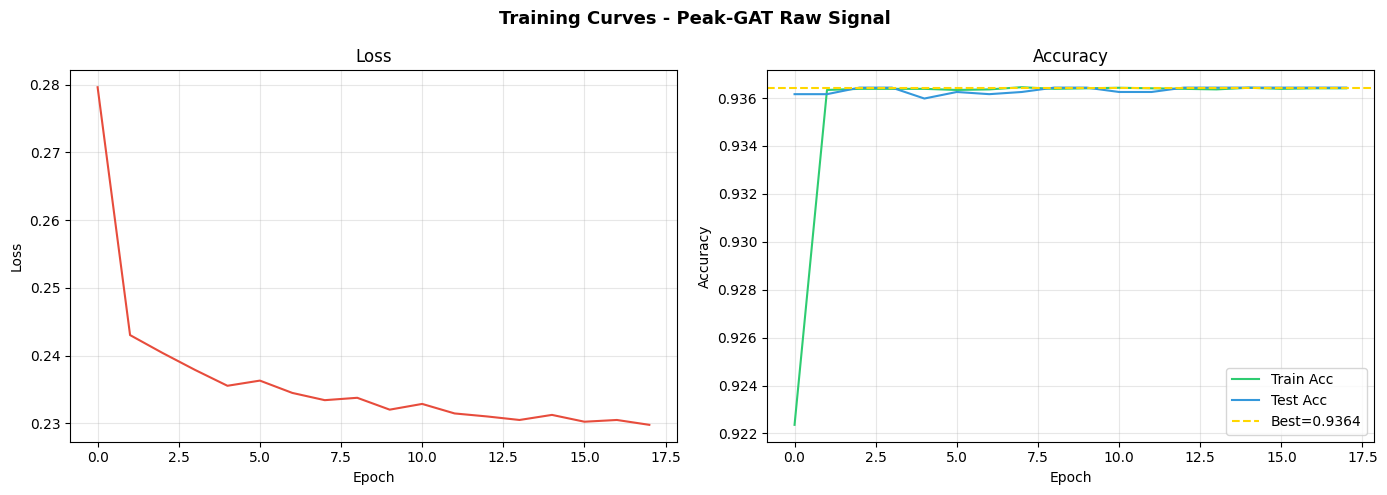

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Training Curves - Peak-GAT Raw Signal', fontsize=13, fontweight='bold')
axes[0].plot(train_losses, color='#e74c3c', label='Train Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].set_title('Loss'); axes[0].grid(True, alpha=0.3)
axes[1].plot(train_accs, color='#2ecc71', label='Train Acc')
axes[1].plot(test_accs,  color='#3498db', label='Test Acc')
axes[1].axhline(best_test_acc, color='gold', linestyle='--', label=f'Best={best_test_acc:.4f}')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].set_title('Accuracy')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('training_curves_binary_unweighted.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 📋 CELL 13: Evaluation — Classification Report & Confusion Matrix

Classification Report - Peak-GAT Raw Signal Pipeline
              precision    recall  f1-score   support

    Elephant       0.94      1.00      0.97     10283
  Wildebeest       0.00      0.00      0.00       698

    accuracy                           0.94     10981
   macro avg       0.47      0.50      0.48     10981
weighted avg       0.88      0.94      0.91     10981



/jupyter/aswin.vs/.local/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/jupyter/aswin.vs/.local/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


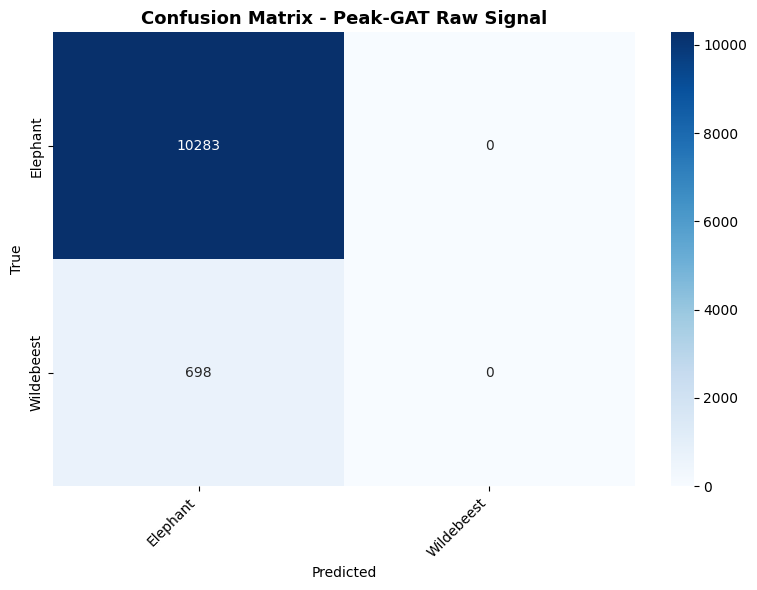

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
_, preds, true_labels = evaluate(model, test_loader)

rev_label_map = {v: k for k, v in label_map.items()}
target_names  = [SPECIES_NAMES.get(rev_label_map[i], f'Class {i}') for i in range(num_classes)]

print('=' * 60)
print('Classification Report - Peak-GAT Raw Signal Pipeline')
print('=' * 60)
print(classification_report(true_labels, preds, target_names=target_names))

cm = confusion_matrix(true_labels, preds)
plt.figure(figsize=(max(8, num_classes), max(6, num_classes - 1)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix - Peak-GAT Raw Signal', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig('confusion_matrix_binary_unweighted.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 📦 CELL 14: Edge-Deployable Tiny Model (INT8 Quantized)

- **4× smaller** model file
- **~2-3× faster** inference on CPU
- Ideal for Raspberry Pi / IoT sensors in the wild

In [ ]:
model.load_state_dict(torch.load(MODEL_PATH, map_location='cpu'))
model_cpu = model.to('cpu'); model_cpu.eval()

tiny_model = torch.quantization.quantize_dynamic(
    model_cpu, {nn.Linear}, dtype=torch.qint8)

TINY_MODEL_PATH = 'tiny_binary_unweighted_int8.pth'
torch.save(tiny_model.state_dict(), TINY_MODEL_PATH)

fp32_size = os.path.getsize(MODEL_PATH)      / 1024
int8_size = os.path.getsize(TINY_MODEL_PATH) / 1024
print('=' * 50)
print('Edge-Deployable Tiny Model (INT8 Quantized)')
print('=' * 50)
print(f'FP32 model: {fp32_size:.1f} KB')
print(f'INT8 model: {int8_size:.1f} KB')
print(f'Reduction : {fp32_size/int8_size:.1f}x smaller')
print(f'Saved to  : {TINY_MODEL_PATH}')
print('\nThis model can run on a Raspberry Pi or embedded sensor.')
print('Pipeline: Read X,Y,Z -> Compute magnitude -> Find peaks -> Build graph -> Run INT8 inference')

---
## 📝 CELL 15: Summary — Paper Table Entry

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
final_acc = accuracy_score(true_labels, preds)
final_f1  = f1_score(true_labels, preds, average='weighted')
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('=' * 65)
print('PAPER SUMMARY - Peak-GAT (Raw Signal, No Spectrogram)')
print('=' * 65)
print(f'  Method          : Peak-Based GAT on Raw 3D Seismic Signal')
print(f'  Input Type      : Raw signal (3 x 2048) - NO spectrogram')
print(f'  Node Features   : 8D (magnitude, X/Y/Z, prominence, energy, std, position)')
print(f'  Architecture    : 3-layer GAT (multi-head attention)')
print(f'  Hidden Dim      : {BEST_PARAMS["hidden_dim"]}')
print(f'  Attention Heads : {BEST_PARAMS["num_heads"]}')
print(f'  Total Params    : {total_params:,}')
print(f'  Best Test Acc   : {best_test_acc:.4f}')
print(f'  Final Test Acc  : {final_acc:.4f}')
print(f'  Weighted F1     : {final_f1:.4f}')
print(f'  INT8 Model Size : {int8_size:.1f} KB')
print(f'  Edge-Deployable : YES')
print(f'  Preprocessing   : O(N) only - no FFT')
print('=' * 65)